In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT / 'src'))

from cevns_pyeft.kernels.basis import coeff_vector_from_triplets, li2026_left_basis_current
from cevns_pyeft.kernels.reconstruction import reconstruct_real_events_from_full_kernel
from cevns_pyeft.experiments.coherent.slow_counts_ar2020 import slow_counts_ar2020

REFERENCE_DIR = ROOT / 'tests' / 'reference_fast_split'
RESPONSES = ROOT / 'data' / 'responses' / 'responses_all.json'
STEM = 'ar2020'
EXPERIMENT = 'Ar2020'
RTOL, ATOL = (1.0e-12, 1.0e-10)


In [2]:
basis = li2026_left_basis_current()
coeff = coeff_vector_from_triplets(basis, {}, include_sm=True)
full_kernel = np.load(REFERENCE_DIR / f'{STEM}_full_kernel.npy')
metadata = __import__('json').loads((REFERENCE_DIR / f'{STEM}_metadata.json').read_text())
raw = reconstruct_real_events_from_full_kernel(full_kernel, coeff)
channel_summed = raw.sum(axis=2)
target_index = metadata['targets'].index('CsI') if 'CsI' in metadata['targets'] else 0
flavor_index = {flavor: metadata['source_flavors'].index(flavor) for flavor in ('mu', 'e', 'mub')}
fast_counts = {flavor: channel_summed[target_index, flavor_index[flavor]] for flavor in ('mu', 'e', 'mub')}
fast_counts['total'] = fast_counts['mu'] + fast_counts['e'] + fast_counts['mub']
slow_counts = slow_counts_ar2020(RESPONSES, include_sm=True, n_er=3, n_enu=6, n_pe_bin=3)['counts_per_bin']
pe_bins = np.asarray(metadata['pe_bins'], dtype=float)
centers = 0.5 * (pe_bins[:-1] + pe_bins[1:])
print({k: np.asarray(v, dtype=float) for k, v in fast_counts.items()})


{'mu': array([7.49301299e-02, 2.29573827e-05, 6.01657413e-12, 1.72919832e-18,
       5.29605525e-25, 1.66140332e-31, 5.31935884e-38, 1.72726564e-44,
       5.66676737e-51, 1.87383205e-57, 6.23480637e-64, 2.08495807e-70]), 'e': array([6.91033698e-02, 9.70765943e-01, 3.41437868e+00, 1.15348458e-01,
       2.16009514e-05, 3.23188733e-10, 1.36328804e-15, 2.79315461e-21,
       3.64874138e-27, 3.53419112e-33, 2.77842391e-39, 1.87760211e-45]), 'mub': array([7.33767603e-02, 3.95954101e+00, 1.39267252e+01, 4.70488609e-01,
       8.81069564e-05, 1.31823710e-09, 5.56064212e-15, 1.13928478e-20,
       1.48826546e-26, 1.44154217e-32, 1.13327635e-38, 7.65845003e-45]), 'total': array([2.17410260e-01, 4.93032991e+00, 1.73411039e+01, 5.85837067e-01,
       1.09707908e-04, 1.64142584e-09, 6.92393016e-15, 1.41860024e-20,
       1.85313959e-26, 1.79496128e-32, 1.41111875e-38, 9.53605214e-45])}


In [3]:
fast_total = np.asarray(fast_counts['total'], dtype=float)
slow_total = np.asarray(slow_counts['total'], dtype=float)
assert fast_total.shape == slow_total.shape == centers.shape
assert np.issubdtype(fast_total.dtype, np.floating)
assert np.all(np.isfinite(fast_total))
assert np.all(np.isfinite(slow_total))
np.testing.assert_allclose(fast_total, slow_total, rtol=RTOL, atol=ATOL)
max_abs_diff = float(np.max(np.abs(fast_total - slow_total)))
summary = {
    'experiment': EXPERIMENT,
    'bins': int(fast_total.size),
    'fast_total': float(np.sum(fast_total)),
    'slow_total': float(np.sum(slow_total)),
    'max_abs_diff': max_abs_diff,
    'status': 'PASS',
}
summary


{'experiment': 'Ar2020',
 'bins': 12,
 'fast_total': 23.074790816770623,
 'slow_total': 23.07479081677062,
 'max_abs_diff': 3.552713678800501e-15,
 'status': 'PASS'}

{'experiment': 'Ar2020', 'bins': 12, 'fast_total': 23.074790816770623, 'slow_total': 23.07479081677062, 'max_abs_diff': 3.552713678800501e-15, 'status': 'PASS'}


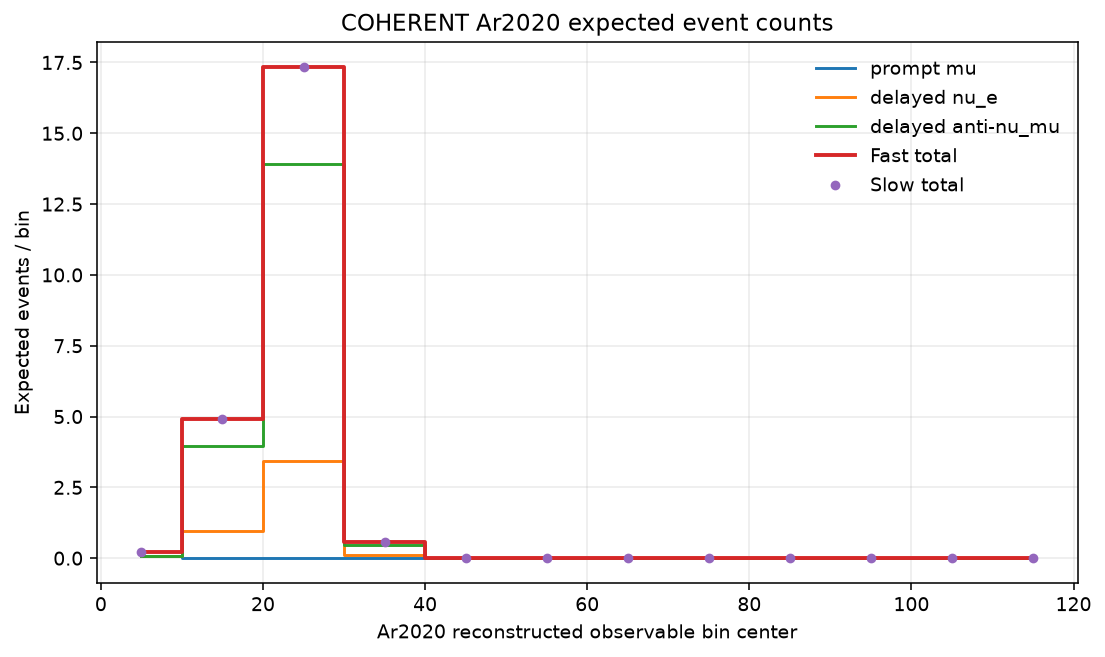

In [4]:
fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=140)
ax.step(centers, fast_counts['mu'], where='mid', label='prompt mu')
ax.step(centers, fast_counts['e'], where='mid', label='delayed nu_e')
ax.step(centers, fast_counts['mub'], where='mid', label='delayed anti-nu_mu')
ax.step(centers, fast_counts['total'], where='mid', linewidth=2.0, label='Fast total')
ax.plot(centers, slow_counts['total'], 'o', markersize=4.0, label='Slow total')
ax.set_title('COHERENT Ar2020 expected event counts')
ax.set_xlabel('Ar2020 reconstructed observable bin center')
ax.set_ylabel('Expected events / bin')
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
print(summary)
